# EDS 220 HW 4 - Task 2

Kailani Latimer

11/19/2026

## 1. Setup and Exploration

In [3]:
# Importing packages
import os                        # build file paths
import numpy as np               # np.isnan() to find NaN values (section 5)
import geopandas as gpd          # read + work with the fire perimeters (vector data)
import xarray as xr              # open the Landsat .nc file (raster data)
import rioxarray                 # adds .rio to xarray: .rio.crs, .rio.write_crs() (section 4)
import matplotlib.pyplot as plt  # make the final map

In [4]:
# Load in the data
eaton = gpd.read_file(os.path.join('data', 'Eaton_Perimeter_20250121.geojson'))
pali = gpd.read_file(os.path.join('data', 'Palisades_Perimieter_20250121.geojson'))
landsat = xr.open_dataset(os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc'))

CRS: EPSG:4326


<Axes: >

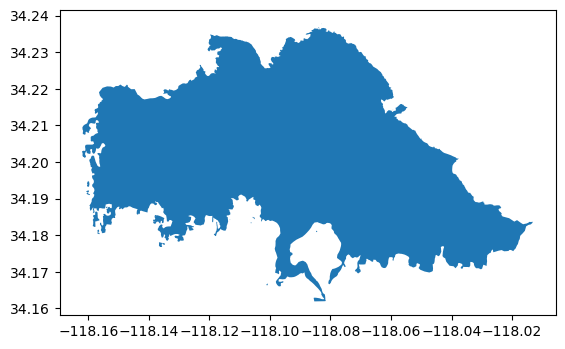

In [7]:
# Exploring the Eaton data
print('CRS:', eaton.crs)
eaton.plot()

CRS: EPSG:4326


<Axes: >

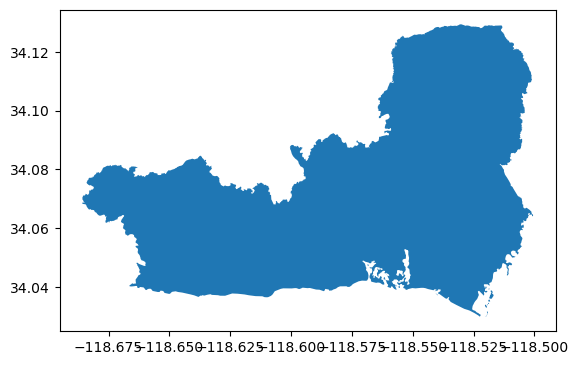

In [8]:
# Exploring the Palisades data
print('CRS:', pali.crs)
pali.plot()

In [ ]:
# Exploring landsat data
landsat.head()

<xarray.Dataset> Size: 596B
Dimensions:      (y: 5, x: 5)
Coordinates:
  * y            (y) float64 40B 3.799e+06 3.799e+06 ... 3.799e+06 3.799e+06
  * x            (x) float64 40B 3.344e+05 3.344e+05 ... 3.345e+05 3.345e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 100B ...
    green        (y, x) float32 100B ...
    blue         (y, x) float32 100B ...
    nir08        (y, x) float32 100B ...
    swir22       (y, x) float32 100B ...
    spatial_ref  int64 8B ...

In [ ]:
landsat.info()

xarray.Dataset {
dimensions:
	y = 1418 ;
	x = 2742 ;

variables:
	float64 y(y) ;
		y:units = metre ;
		y:resolution = -30.0 ;
		y:crs = EPSG:32611 ;
		y:axis = Y ;
		y:long_name = y coordinate of projection ;
		y:standard_name = projection_y_coordinate ;
	float64 x(x) ;
		x:units = metre ;
		x:resolution = 30.0 ;
		x:crs = EPSG:32611 ;
		x:axis = X ;
		x:long_name = x coordinate of projection ;
		x:standard_name = projection_x_coordinate ;
	datetime64[ns] time() ;
	float32 red(y, x) ;
		red:grid_mapping = spatial_ref ;
	float32 green(y, x) ;
		green:grid_mapping = spatial_ref ;
	float32 blue(y, x) ;
		blue:grid_mapping = spatial_ref ;
	float32 nir08(y, x) ;
		nir08:grid_mapping = spatial_ref ;
	float32 swir22(y, x) ;
		swir22:grid_mapping = spatial_ref ;
	int64 spatial_ref() ;
		spatial_ref:crs_wkt = PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["

In [19]:
landsat.coords

Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...

In [23]:
landsat.dims

FrozenMappingWarningOnValuesAccess({'y': 1418, 'x': 2742})

In [24]:
landsat.data_vars

Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...